# 01. Podstawy i odczyt

**Poziom: Podstawy**


## Spis treści

- [Problem](#sekcja-01)
- [Po tej części potrafisz](#sekcja-02)
- [Wykonanie](#sekcja-03)
- [1. Co daje `std::variant`?](#sekcja-04)
    - [Dlaczego nie zapisać po prostu dwóch pól?](#sekcja-05)
    - [Ręczna flaga i variant: ten sam zapis, inny skutek](#sekcja-06)
- [2. Pierwszy program: zapis i odczyt](#sekcja-07)
    - [Numer przechowywanego typu: `index()`](#sekcja-08)
    - [Inny sposób zapisania wartości: `emplace`](#sekcja-09)
    - [Co się stanie bez podania wartości początkowej?](#sekcja-10)
    - [Demonstracja: Zmiana wartości i indeksu](#sekcja-11)
- [3. Skąd wiedzieć, co jest w środku?](#sekcja-12)
    - [`holds_alternative`: sprawdź typ](#sekcja-13)
    - [`get_if`: spróbuj uzyskać dostęp do wartości](#sekcja-14)
    - [`get`: odczytaj albo otrzymaj wyjątek](#sekcja-15)
    - [Dwie rzeczy, na które trzeba uważać](#sekcja-16)
    - [Demonstracja: Trzy sposoby dostępu do wartości](#sekcja-17)
- [Artykuły i dokumentacja](#sekcja-18)
    - [Artykuły z przykładami](#sekcja-19)
    - [Dokumentacja konkretnych operacji](#sekcja-20)


<a id="sekcja-01"></a>

## Problem

Chcemy w **jednej zmiennej** przechowywać **liczbę albo tekst**, jedną wartość naraz. Potrzebujemy też sposobu na sprawdzenie, który typ jest aktualnie zapisany, i bezpieczny odczyt tej wartości.

<a id="sekcja-02"></a>

## Po tej części potrafisz

- Wyjaśnić, co zmienia się podczas zastępowania liczby tekstem.
- Bezpiecznie odczytać wartość przez get lub get_if i sprawdzić typ.
- Rozpoznać niespójność ręcznej flagi i porównać ją z wariantem.

<a id="sekcja-03"></a>

## Wykonanie

Wybierz kernel Python 3 i wykonaj komórki od góry. Poniższa komórka Python przygotowuje `%%cpp`; każda komórka C++ zawiera własne nagłówki, definicje i `main()`. W razie problemu wróć do [sprawdzenia środowiska](00_start.ipynb).


In [1]:
import os
import shutil
import subprocess
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.core.magic import register_cell_magic

COMPILER_NAME = os.environ.get("CXX", "c++")

@register_cell_magic
def cpp(line: str, cell: str) -> None:
    """Kompiluje i uruchamia jedną niezależną demonstrację C++17."""
    option = line.strip()
    if option not in {"", "--expect-error"}:
        raise ValueError("Użyj %%cpp albo %%cpp --expect-error.")
    expect_error = option == "--expect-error"
    compiler = shutil.which(COMPILER_NAME)
    if compiler is None:
        raise RuntimeError(
            f"Nie znaleziono kompilatora {COMPILER_NAME!r}. "
            "Zainstaluj kompilator C++17 lub ustaw COMPILER_NAME."
        )
    with TemporaryDirectory(prefix="variant-notebook-") as directory:
        source = Path(directory) / "example.cpp"
        executable = Path(directory) / ("example.exe" if os.name == "nt" else "example")
        source.write_text(cell, encoding="utf-8")
        compiled = subprocess.run(
            [compiler, "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
             str(source), "-o", str(executable)],
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=60,
        )
        if expect_error:
            if compiled.returncode == 0:
                raise RuntimeError("Oczekiwano błędu kompilacji, ale program skompilował się poprawnie.")
            print("Oczekiwany błąd kompilacji. Początek komunikatu kompilatora:")
            diagnostics = (compiled.stdout + compiled.stderr).replace(str(source), "example.cpp").splitlines()
            print("\n".join(diagnostics[:16]))
            if len(diagnostics) > 16:
                print("[Dalsza część komunikatu została pominięta.]")
            return
        if compiled.returncode != 0:
            raise RuntimeError("Błąd kompilacji:\n" + compiled.stdout + compiled.stderr)
        executed = subprocess.run(
            [str(executable)], capture_output=True, text=True,
            encoding="utf-8", errors="replace", timeout=10,
        )
        print(executed.stdout, end="")
        if executed.stderr:
            print(executed.stderr, end="")
        if executed.returncode != 0:
            raise RuntimeError(f"Program zakończył się kodem {executed.returncode}.")

print(f"Gotowe: %%cpp używa {COMPILER_NAME}, standard C++17.")

Gotowe: %%cpp używa c++, standard C++17.


<a id="sekcja-04"></a>

## 1. Co daje `std::variant`?

Zwykła zmienna ma ustalony typ: `int` przechowuje liczbę, a `std::string` tekst. Czasem potrzebujemy jednak jednej zmiennej, która może przechowywać **liczbę albo tekst**. `std::variant<int, std::string>` pozwala zapisać taki wybór. W danej chwili przechowuje jedną wartość - zapisanie tekstu zastępuje poprzednią liczbę.

Wyobraźmy sobie, że tworzymy klienta API, czyli program pobierający dane z serwera. Potrzebuje on ustawień: liczby prób połączenia, np. `3`, oraz adresu serwera, np. `"localhost"`. Dla wartości tych ustawień chcemy mieć wspólny typ: liczbę albo tekst. Wariant będzie przechowywał wartość pojedynczego ustawienia.

`std::variant` pozwala zadeklarować taki typ:


In [2]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};

    std::cout << std::get<int>(wartosc) << '\n';
}


42


Przeczytaj deklarację `wartosc` tak: **„Zmienna `wartosc` może przechowywać liczbę typu `int` albo tekst typu `std::string`. Na początku przechowuje liczbę 42”.**

Rozłóżmy zapis na części:

- `std::variant` to narzędzie z biblioteki standardowej C++.
- `<int, std::string>` to lista dozwolonych typów. Ustalasz ją przy deklaracji.
- `wartosc` to nazwa zmiennej.
- `{42}` podaje początkową wartość.

W takim wariancie przechowujesz **jedną wartość naraz**. Gdy zapiszesz tekst, zastąpi on poprzednią liczbę.


In [3]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42}; // teraz liczba
    wartosc = std::string{"localhost"}; // teraz tekst

    std::cout << std::get<std::string>(wartosc) << '\n';
}


localhost


`std::string{"localhost"}` tworzy obiekt typu `std::string` z podanego tekstu. Dzięki jawnemu zapisowi widać, który typ chcemy umieścić w wariancie.

**Typ samej zmiennej `wartosc` się nie zmienia:** cały czas jest to `std::variant<int, std::string>`. Zmienia się to, który z dwóch dozwolonych typów jest w niej aktualnie przechowywany.

Każdy typ z listy nazywamy **alternatywą**. „Aktywna alternatywa” oznacza po prostu typ przechowywany w tej chwili: najpierw `int`, potem `std::string`.

<a id="sekcja-05"></a>

### Dlaczego nie zapisać po prostu dwóch pól?

Można stworzyć strukturę z polami `int liczba`, `std::string tekst` i dodatkową informacją, z którego pola należy korzystać. Wtedy oba pola istnieją jednocześnie, a programista musi pilnować tej dodatkowej informacji.

`variant` sam pamięta, którą wartość przechowuje, i kontroluje dostęp do niej. Nie musisz osobno utrzymywać flagi „teraz używamy tekstu”. W rozdziale [Praktyczne zastosowania](03_zastosowania.ipynb) wykorzystamy to do przechowywania ustawień klienta oraz wyniku operacji: sukcesu albo błędu.


<a id="sekcja-06"></a>

### Ręczna flaga i variant: ten sam zapis, inny skutek

W pierwszej wersji zmieniamy tekst, ale zapominamy zmienić flagę. Program się kompiluje i nadal odczytuje liczbę 3. Druga wersja używa `variant`, który aktualizuje informację o typie razem z wartością. Oba przypadki można porównać w jednej komórce.


In [4]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

struct ManualValue {
    bool is_text;
    int number;
    std::string text;
};

int main() {
    ManualValue manual{false, 3, {}};
    manual.text = "example.org"; // Zapomniano zmienić flagę is_text.
    std::cout << "reczna flaga: " << (manual.is_text ? manual.text : std::to_string(manual.number))
              << '\n';

    std::variant<int, std::string> value{3};
    value = std::string{"example.org"};
    std::cout << "variant: " << std::get<std::string>(value) << '\n';
}


reczna flaga: 3
variant: example.org


Ręczna flaga i pola mogą opisywać sprzeczne informacje. `variant` pilnuje zgodności typu i przechowywanej wartości, ale nie sprawdza reguł biznesowych ustawienia, np. nieujemnej liczby prób.


<a id="sekcja-07"></a>

## 2. Pierwszy program: zapis i odczyt

Zacznijmy od niewielkiego programu pokazującego zapis i odczyt wartości. Uruchom poniższą komórkę, aby zobaczyć liczbę, a następnie zastępujący ją tekst.


In [5]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    std::cout << std::get<int>(wartosc) << '\n';

    wartosc = std::string{"localhost"};
    std::cout << std::get<std::string>(wartosc) << '\n';
}


42
localhost


Nagłówek `<variant>` udostępnia `std::variant` i funkcje dostępu do wartości. `<string>` jest potrzebny dla `std::string`, a `<iostream>` do wypisywania.

Zwróć uwagę na dwie operacje:

1. **Zapis:** `wartosc = std::string{"localhost"};` zastępuje liczbę tekstem.
2. **Odczyt:** `std::get<std::string>(wartosc)` pobiera przechowywany tekst.

W zapisie `std::get<int>(wartosc)` część `<int>` oznacza: **„chcę odczytać liczbę typu `int`”**. Nie jest to polecenie zamiany tekstu na liczbę. Jeśli w środku jest tekst, taki odczyt się nie powiedzie. Za chwilę pokażemy, jak to sprawdzać.

`get` daje dostęp przez referencję do wartości znajdującej się w wariancie. W powyższym programie po prostu przekazujemy ją do `std::cout`.

<a id="sekcja-08"></a>

### Numer przechowywanego typu: `index()`

Typy na liście są ponumerowane od zera. Dla `std::variant<int, std::string>`:

- indeks **0** oznacza `int`;
- indeks **1** oznacza `std::string`.


In [6]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    std::cout << wartosc.index() << '\n'; // 0
    wartosc = std::string{"localhost"};
    std::cout << wartosc.index() << '\n'; // 1
}


0
1


Możesz też użyć numeru do odczytu: `std::get<0>(wartosc)` wybiera pierwszą alternatywę, a `std::get<1>(wartosc)` drugą. Numer oznacza **pozycję typu na liście**, nie przechowywaną liczbę. Zwykle zapis przez typ, np. `get<std::string>`, łatwiej zrozumieć.

<a id="sekcja-09"></a>

### Inny sposób zapisania wartości: `emplace`

Przypisanie, które już znasz, wystarczy w wielu sytuacjach. `emplace` pozwala wskazać typ i przekazać argumenty do utworzenia nowej wartości bezpośrednio w wariancie:


In [7]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    wartosc.emplace<std::string>("localhost");
    std::cout << std::get<std::string>(wartosc) << '\n'; // localhost
}


localhost


Tutaj `emplace<std::string>("localhost")` zastępuje dotychczasową liczbę nowym tekstem. Po tej operacji poprzedniej liczby 42 już w wariancie nie ma.

<a id="sekcja-10"></a>

### Co się stanie bez podania wartości początkowej?


In [8]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc;
    std::cout << std::get<int>(wartosc) << '\n'; // 0
}


0


Wariant zaczyna od **pierwszego typu z listy**. W tym przypadku jest to `int` o wartości 0. Nie zaczyna jako „pusty”. Jeżeli pierwszy typ nie pozwala na utworzenie obiektu bez argumentów, taka deklaracja nie będzie dostępna. Rozwiązanie tego przypadku omawiamy w rozdziale [Pułapki i ograniczenia](04_pulapki.ipynb).

W komórce demonstracyjnej poniżej dodajemy trzeci typ: `double`, czyli liczbę zmiennoprzecinkową. Wariant ma kolejność typów `int, double, std::string`, dlatego tekst ma indeks 2, a liczba zmiennoprzecinkowa - indeks 1. Wynik pojawia się bezpośrednio pod wykonywalną komórką.

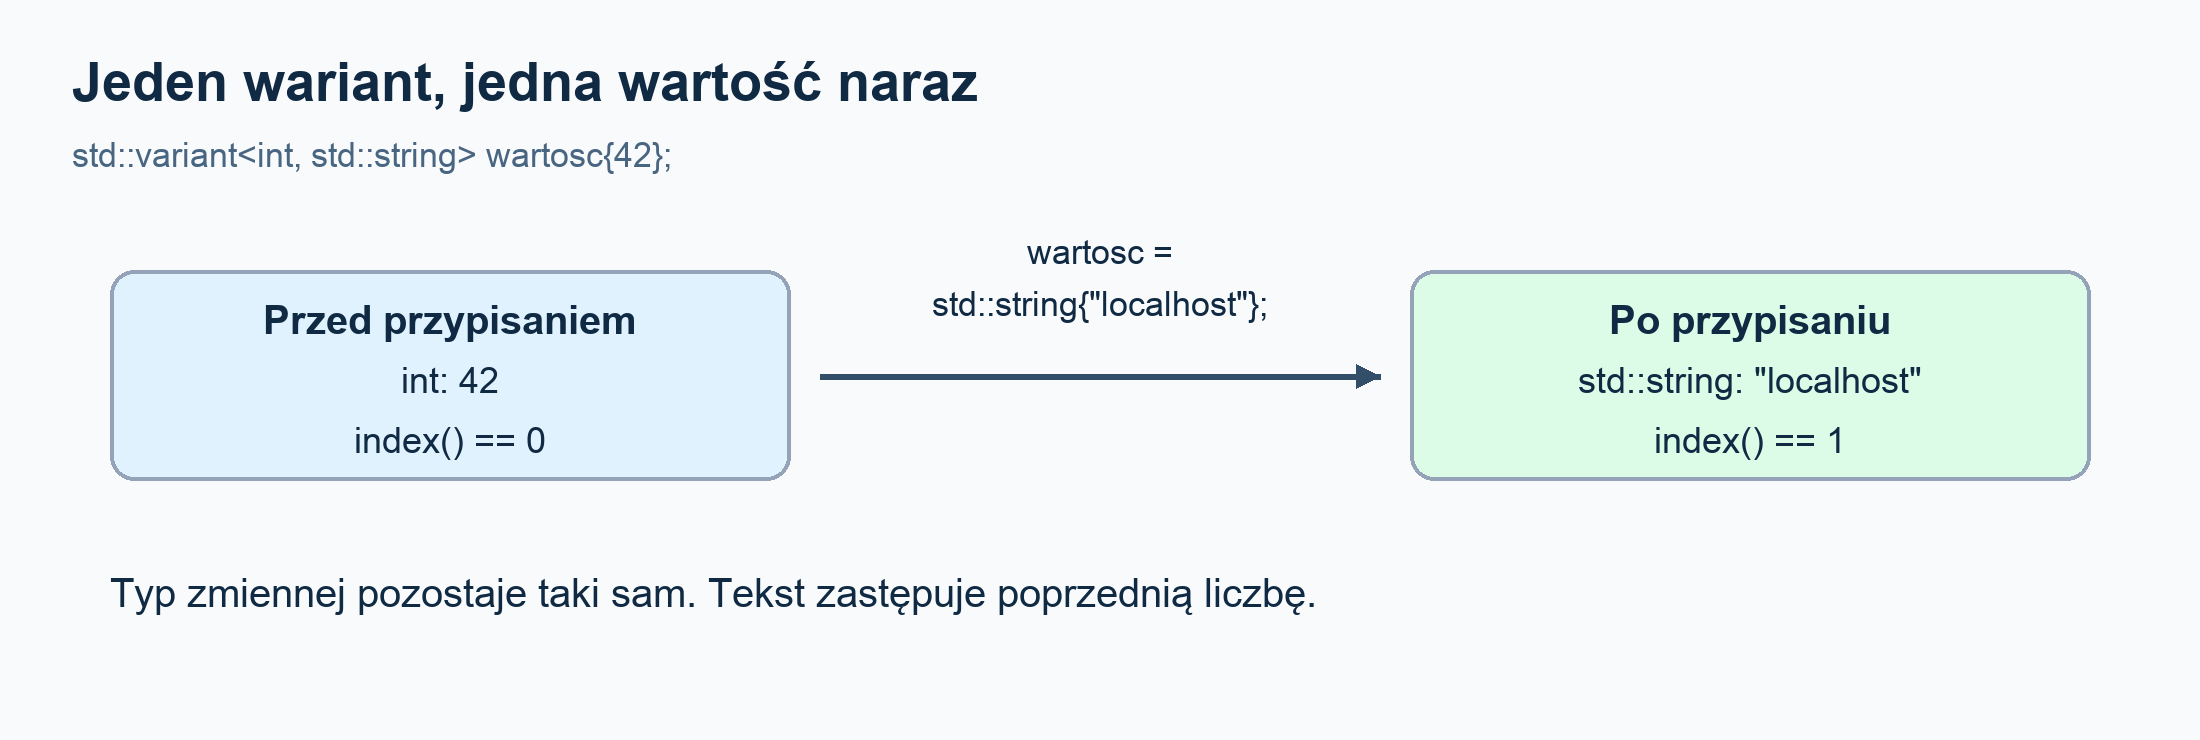

Diagram pokazuje wariant z dwoma typami z wprowadzenia. Demonstracja poniżej rozszerza tę listę o `double`, dlatego indeks tekstu jest w niej inny.


<a id="sekcja-11"></a>

### Demonstracja: Zmiana wartości i indeksu

Kompletna komórka pokazuje kolejno `int`, `std::string` i `double`. Uruchom ją, aby zobaczyć wartość oraz indeks po każdej zmianie.


In [9]:
%%cpp
// Cel: zmiana aktywnej alternatywy bez osobnej flagi typu.
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, double, std::string> value{42};
    std::cout << "int: " << std::get<int>(value) << ", index: " << value.index() << '\n';
    value = std::string{"tekst"};
    std::cout << "string: " << std::get<2>(value) << ", index: " << value.index() << '\n';
    value.emplace<double>(3.5);
    std::cout << "double: " << std::get<double>(value) << ", index: " << value.index() << '\n';
}


int: 42, index: 0
string: tekst, index: 2
double: 3.5, index: 1


**Jak czytać wynik:** Wynik pokazuje kolejno liczbę całkowitą, tekst i liczbę zmiennoprzecinkową. Indeksy wynikają z kolejności `int, double, std::string`.


<a id="sekcja-12"></a>

## 3. Skąd wiedzieć, co jest w środku?

Załóżmy, że otrzymujesz wariant od innej części programu. Nie wiesz, czy przechowuje liczbę, czy tekst. Masz trzy przydatne narzędzia.

<a id="sekcja-13"></a>

### `holds_alternative`: sprawdź typ

`std::holds_alternative<int>(wartosc)` odpowiada na pytanie: **„Czy w tej chwili w środku jest `int`?”**. Wynikiem jest `true` albo `false`.


In [10]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    if (std::holds_alternative<int>(wartosc)) {
        std::cout << std::get<int>(wartosc) << '\n'; // 42
    }
}


42


Najpierw sprawdzamy typ, a potem odczytujemy pasującą wartość. Samo `holds_alternative` niczego nie pobiera ani nie zmienia.

<a id="sekcja-14"></a>

### `get_if`: spróbuj uzyskać dostęp do wartości

`std::get_if<int>(&wartosc)` próbuje uzyskać dostęp do liczby. Zwraca **wskaźnik do liczby**, jeśli jest ona w środku. Jeżeli w środku jest tekst, zwraca `nullptr`, czyli pusty wskaźnik.


In [11]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    int* liczba = std::get_if<int>(&wartosc);

    if (liczba != nullptr) {
        std::cout << *liczba << '\n'; // 42
    } else {
        std::cout << "W środku nie ma liczby\n";
    }
}


42


Znaczenie symboli w tym przykładzie:

- `&wartosc` przekazuje adres wariantu - tego wymaga `get_if`.
- `int* liczba` deklaruje wskaźnik do `int`.
- `liczba != nullptr` sprawdza, czy uzyskaliśmy dostęp do liczby.
- `*liczba` odczytuje wartość spod wskaźnika. Robimy to dopiero po sprawdzeniu, że wskaźnik nie jest pusty.

Jeżeli w pierwszej linii wpiszesz `std::string{"localhost"}` zamiast `42`, wykona się gałąź `else`. `get_if` nie rzuca wyjątku tylko dlatego, że w środku jest inny dozwolony typ.

<a id="sekcja-15"></a>

### `get`: odczytaj albo otrzymaj wyjątek

`get` już poznaliśmy. Gdy prosisz o typ, który jest na liście, ale nie jest teraz przechowywany, rzuca wyjątek `std::bad_variant_access`.


In [12]:
%%cpp
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> wartosc{42};
    try {
        std::cout << std::get<std::string>(wartosc) << '\n';
    } catch (const std::bad_variant_access&) {
        std::cout << "Nie mozna odczytac tekstu: w srodku jest liczba\n";
    }
}


Nie mozna odczytac tekstu: w srodku jest liczba


`try` obejmuje operację, która może rzucić wyjątek. `catch` przechwytuje wskazany rodzaj wyjątku, dzięki czemu ten program wypisze komunikat zamiast zakończyć się z nieobsłużonym wyjątkiem.

**Którego narzędzia użyć?** Gdy chcesz tylko sprawdzić typ, wybierz `holds_alternative`. Gdy inny typ jest spodziewaną sytuacją i potrzebujesz wartości, wygodne jest `get_if`. `get` daje bezpośredni dostęp z kontrolą przez wyjątek, jeśli wybrana alternatywa nie pasuje.

Komórka demonstracyjna poniżej zestawia wszystkie trzy narzędzia: sprawdzenie typu przez `holds_alternative`, próbę odczytu przez `get_if` oraz odczyt przez `get` z przechwyceniem wyjątku. Po zmianie wartości na tekst pokazuje też udany odczyt przez wskaźnik.

<a id="sekcja-16"></a>

### Dwie rzeczy, na które trzeba uważać

**Typ musi być na liście.** Dla `std::variant<int, std::string>` próba użycia `std::get<double>` jest błędem kompilacji, bo `double` nie jest dozwoloną alternatywą. Tego błędu nie przechwycisz przez `catch`: program nie zostanie zbudowany. Ta sama zasada dotyczy `get_if` i `holds_alternative`.

**Nie zachowuj dostępu do starej wartości po jej zniszczeniu.** Jeśli `get_if` zwróci wskaźnik do liczby, a później zastąpisz ją tekstem, nie wolno już używać tego wskaźnika do odczytu poprzedniej liczby. Dotyczy to także referencji uzyskanej przez `get`.

W rozdziale [Pułapki i ograniczenia](04_pulapki.ipynb) poznasz szczególny przypadek, w którym wyjątek podczas zmiany wartości może pozostawić wariant bez żadnej wartości. Na razie pracowaliśmy z wariantami zawierającymi liczbę lub tekst.

**Przed przejściem dalej:** wiesz już, jak zadeklarować dozwolone typy, zapisać jedną z wartości i bezpiecznie ją odczytać. W następnym rozdziale pokażemy `std::visit`, które pozwala opisać operację dla każdego typu bez ręcznego sprawdzania go w kolejnych instrukcjach `if`.


<a id="sekcja-17"></a>

### Demonstracja: Trzy sposoby dostępu do wartości

Wykonaj komórkę, aby zobaczyć różnicę między sprawdzeniem typu, pustym wskaźnikiem i przechwyconym wyjątkiem.


In [13]:
%%cpp
// Cel: odróżnienie odczytu rzucającego wyjątek od sprawdzania wskaźnika.
#include <iostream>
#include <string>
#include <variant>

int main() {
    std::variant<int, std::string> value{7};
    std::cout << "get<int>: " << std::get<int>(value) << '\n';
    std::cout << std::boolalpha << "holds string: " << std::holds_alternative<std::string>(value) << '\n';
    if (std::get_if<std::string>(&value) == nullptr) {
        std::cout << "get_if<string>: nullptr\n";
    }
    try {
        (void)std::get<std::string>(value);
    } catch (const std::bad_variant_access&) {
        std::cout << "get<string>: bad_variant_access\n";
    }
    value = std::string{"gotowe"};
    if (const auto* text = std::get_if<std::string>(&value)) {
        std::cout << "get_if<string>: " << *text << '\n';
    }
}


get<int>: 7
holds string: false
get_if<string>: nullptr
get<string>: bad_variant_access
get_if<string>: gotowe


**Jak czytać wynik:** Najpierw aktywny jest `int`: sprawdzenie tekstu daje `false`, `get_if` zwraca `nullptr`, a `get` rzuca przechwycony wyjątek. Po przypisaniu tekstu odczyt przez wskaźnik się udaje.


<a id="sekcja-18"></a>

## Artykuły i dokumentacja

<a id="sekcja-19"></a>

### Artykuły z przykładami

- [C++ Stories: Everything You Need to Know About std::variant](https://www.cppstories.com/2018/06/variant/) - wprowadzenie i praktyczne zastosowania.

<a id="sekcja-20"></a>

### Dokumentacja konkretnych operacji

- [cppreference: std::variant](https://en.cppreference.com/cpp/utility/variant) - operacje i wymagania wariantu.
- [cppreference: std::get](https://en.cppreference.com/cpp/utility/variant/get) - odczyt przez typ lub indeks.
- [cppreference: std::get_if](https://en.cppreference.com/cpp/utility/variant/get_if) - odczyt przez wskaźnik i nullptr.

W artykułach i dokumentacji występują także rozszerzenia późniejszych standardów. Przykłady tego rozdziału pozostają w C++17.


[Poprzednia część](00_start.ipynb) | [Start](00_start.ipynb) | [Pełny przewodnik](../PRZEWODNIK.md) | [Następny rozdział](02_visit.ipynb)
